**LOAD MASK TỪ MODEL VNET3D**

In [3]:
 # !pip install -q monai nibabel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 29.0 MB/s eta 0:00:00a 0:00:01


In [ ]:
# import os
# import torch
# import torch.nn as nn
# import numpy as np
# import nibabel as nib
# import scipy.ndimage as ndi  # Dùng thư viện này để resize chuẩn y hệt lúc train

# # ==========================================
# # 1. CẤU HÌNH
# # ==========================================
# MODEL_PATH = "/kaggle/input/best-model-seg/best_model.pth" 
# DATA_DIR = "/kaggle/input/m-and-ms-dataset/MnM2/dataset" 
# OUTPUT_DIR = "/kaggle/working/prediction_masks"
# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# TARGET_SIZE = (128, 128, 64)  # Kích thước chuẩn của Model bạn

# # ==========================================
# # 2. KIẾN TRÚC VNet3D (GIỮ NGUYÊN)
# # ==========================================
# class ShortCutConv3D(nn.Module):
#     def __init__(self, in_ch, out_ch):
#         super().__init__()
#         self.conv = nn.Identity() if in_ch == out_ch else nn.Sequential(
#             nn.Conv3d(in_ch, out_ch, 1, bias=False), nn.InstanceNorm3d(out_ch))
#     def forward(self, x): return self.conv(x)

# class VBlock(nn.Module):
#     def __init__(self, in_ch, out_ch):
#         super().__init__()
#         self.conv1 = nn.Conv3d(in_ch, out_ch, 5, padding=2, bias=False)
#         self.in1 = nn.InstanceNorm3d(out_ch); self.prelu1 = nn.PReLU(out_ch)
#         self.conv2 = nn.Conv3d(out_ch, out_ch, 5, padding=2, bias=False)
#         self.in2 = nn.InstanceNorm3d(out_ch); self.prelu2 = nn.PReLU(out_ch)
#         self.short = ShortCutConv3D(in_ch, out_ch)
#     def forward(self, x):
#         sc = self.short(x)
#         out = self.prelu2(self.in2(self.conv2(self.prelu1(self.in1(self.conv1(x))))))
#         return out + sc

# class VNet3D(nn.Module):
#     def __init__(self, num_classes=4, f=16):
#         super().__init__()
#         self.enc1 = VBlock(1, f); self.down1 = nn.Conv3d(f, 2*f, 2, stride=2) 
#         self.enc2 = VBlock(2*f, 2*f); self.down2 = nn.Conv3d(2*f, 4*f, 2, stride=2)
#         self.enc3 = VBlock(4*f, 4*f); self.down3 = nn.Conv3d(4*f, 8*f, 2, stride=2)
#         self.bottleneck = VBlock(8*f, 8*f)
#         self.up3 = nn.ConvTranspose3d(8*f, 8*f, 2, stride=2); self.dec3 = VBlock(12*f, 4*f) 
#         self.up2 = nn.ConvTranspose3d(4*f, 4*f, 2, stride=2); self.dec2 = VBlock(6*f, 2*f)  
#         self.up1 = nn.ConvTranspose3d(2*f, 2*f, 2, stride=2); self.dec1 = VBlock(3*f, f)    
#         self.final = nn.Conv3d(f, num_classes, 1)
#     def forward(self, x):
#         x1 = self.enc1(x); x2 = self.enc2(self.down1(x1)); x3 = self.enc3(self.down2(x2))
#         b = self.bottleneck(self.down3(x3))
#         d3 = self.dec3(torch.cat([self.up3(b), x3], 1))
#         d2 = self.dec2(torch.cat([self.up2(d3), x2], 1))
#         d1 = self.dec1(torch.cat([self.up1(d2), x1], 1))
#         return self.final(d1)

# # ==========================================
# # 3. HELPER XỬ LÝ ẢNH (GIỮ NGUYÊN)
# # ==========================================
# class SegmentationHelper:
#     def __init__(self, model_path, device):
#         self.device = device
#         self.model = VNet3D(num_classes=4).to(self.device)
#         try:
#             self.model.load_state_dict(torch.load(model_path, map_location=self.device))
#             self.model.eval()
#             print("✅ Đã load đúng Model VNet3D!")
#         except Exception as e:
#             print(f"❌ Lỗi load model: {e}")

#     def predict_and_save(self, input_path, output_path):
#         # 1. Load ảnh gốc
#         img_obj = nib.load(input_path)
#         img_data = img_obj.get_fdata().astype(np.float32)
#         orig_shape = img_data.shape # (H, W, D)

#         # 2. Resize
#         zoom_factor = (TARGET_SIZE[0]/orig_shape[0], TARGET_SIZE[1]/orig_shape[1], TARGET_SIZE[2]/orig_shape[2])
#         img_resized = ndi.zoom(img_data, zoom_factor, order=1)

#         # 3. Chuẩn hóa Z-Score
#         img_norm = (img_resized - img_resized.mean()) / (img_resized.std() + 1e-6)

#         # 4. Predict
#         inp_tensor = torch.from_numpy(img_norm[None, None]).float().to(self.device)
#         with torch.no_grad():
#             out_tensor = self.model(inp_tensor)
#             pred_tensor = torch.argmax(out_tensor, dim=1)

#         # 5. Post-process & Save
#         pred_data = pred_tensor[0].cpu().numpy().astype(np.uint8)
#         inv_zoom_factor = (orig_shape[0]/TARGET_SIZE[0], orig_shape[1]/TARGET_SIZE[1], orig_shape[2]/TARGET_SIZE[2])
#         final_mask = ndi.zoom(pred_data, inv_zoom_factor, order=0)

#         final_img = nib.Nifti1Image(final_mask, img_obj.affine, img_obj.header)
#         nib.save(final_img, output_path)

# # ==========================================
# # 4. CHẠY VÒNG LẶP (ĐÃ CẬP NHẬT CẢ ED VÀ ES)
# # ==========================================
# if not os.path.exists(OUTPUT_DIR):
#     os.makedirs(OUTPUT_DIR)

# print(f"🚀 Bắt đầu xử lý dữ liệu với VNet3D (Cả ED và ES)...")
# seg_helper = SegmentationHelper(MODEL_PATH, DEVICE)

# patient_ids = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
# print(f"📂 Tổng số bệnh nhân tìm thấy: {len(patient_ids)}")

# for i, pid in enumerate(patient_ids):
#     # Định nghĩa đường dẫn cho cả ED và ES
#     in_ed = os.path.join(DATA_DIR, pid, f"{pid}_SA_ED.nii")
#     out_ed = os.path.join(OUTPUT_DIR, f"{pid}_SA_ED_mask.nii")
    
#     in_es = os.path.join(DATA_DIR, pid, f"{pid}_SA_ES.nii")
#     out_es = os.path.join(OUTPUT_DIR, f"{pid}_SA_ES_mask.nii")
    
#     status_ed = "❌"
#     status_es = "❌"
    
#     # Xử lý ED
#     if os.path.exists(in_ed):
#         try:
#             seg_helper.predict_and_save(in_ed, out_ed)
#             status_ed = "✅"
#         except Exception as e:
#             status_ed = f"Err: {e}"

#     # Xử lý ES
#     if os.path.exists(in_es):
#         try:
#             seg_helper.predict_and_save(in_es, out_es)
#             status_es = "✅"
#         except Exception as e:
#             status_es = f"Err: {e}"
            
#     # In báo cáo tiến độ mỗi 10 bệnh nhân hoặc bệnh nhân cuối cùng
#     if (i+1) % 10 == 0 or (i+1) == len(patient_ids):
#         print(f"[{i+1}/{len(patient_ids)}] {pid}: ED {status_ed} | ES {status_es}")

 BẮT ĐẦU HỆ THỐNG PHÂN LOẠI TIM MẠCH TỰ ĐỘNG

--- BƯỚC 1: TẢI DỮ LIỆU ---
   -> Số lượng bệnh nhân: 261

--- BƯỚC 2: TÍNH RADIOMICS ---
📂 Đang quét mask từ: /kaggle/input/vnet3d-masks
⏳ Đang tính toán chỉ số y sinh...
✅ Dữ liệu hợp lệ: 261

--- BƯỚC 3: HUẤN LUYỆN ---

🏆 ĐỘ CHÍNH XÁC: 81.13%
------------------------------------------------------------
              precision    recall  f1-score   support

   Left Path       0.82      0.75      0.78        12
  Right Path       0.86      0.91      0.89        34
      Normal       0.50      0.43      0.46         7

    accuracy                           0.81        53
   macro avg       0.73      0.70      0.71        53
weighted avg       0.80      0.81      0.81        53



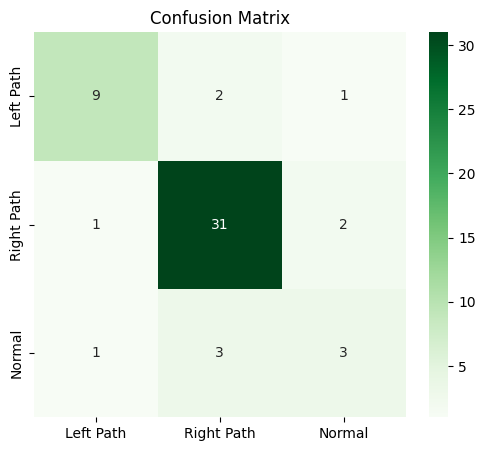

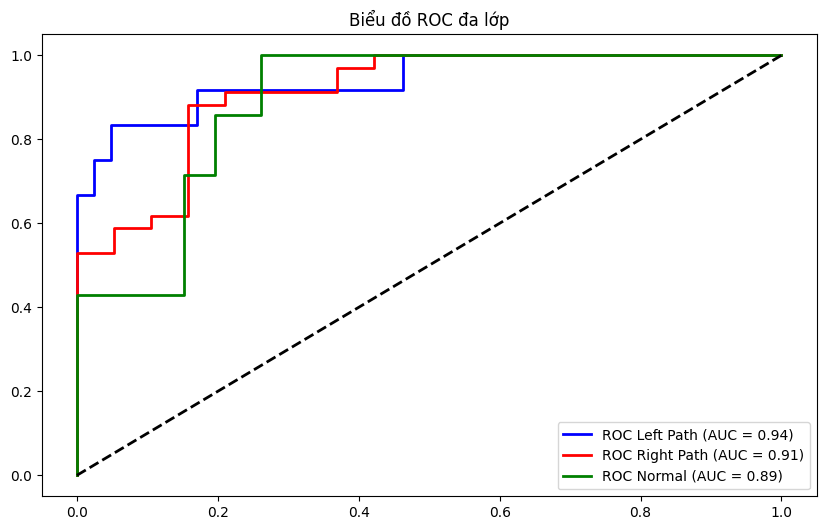

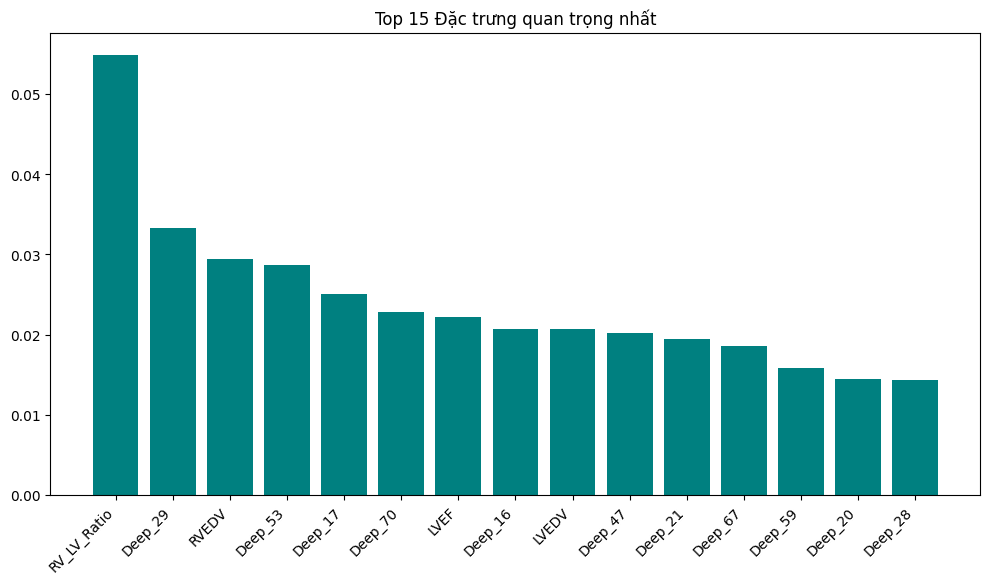


 TRỰC QUAN HÓA 5 BỆNH NHÂN:


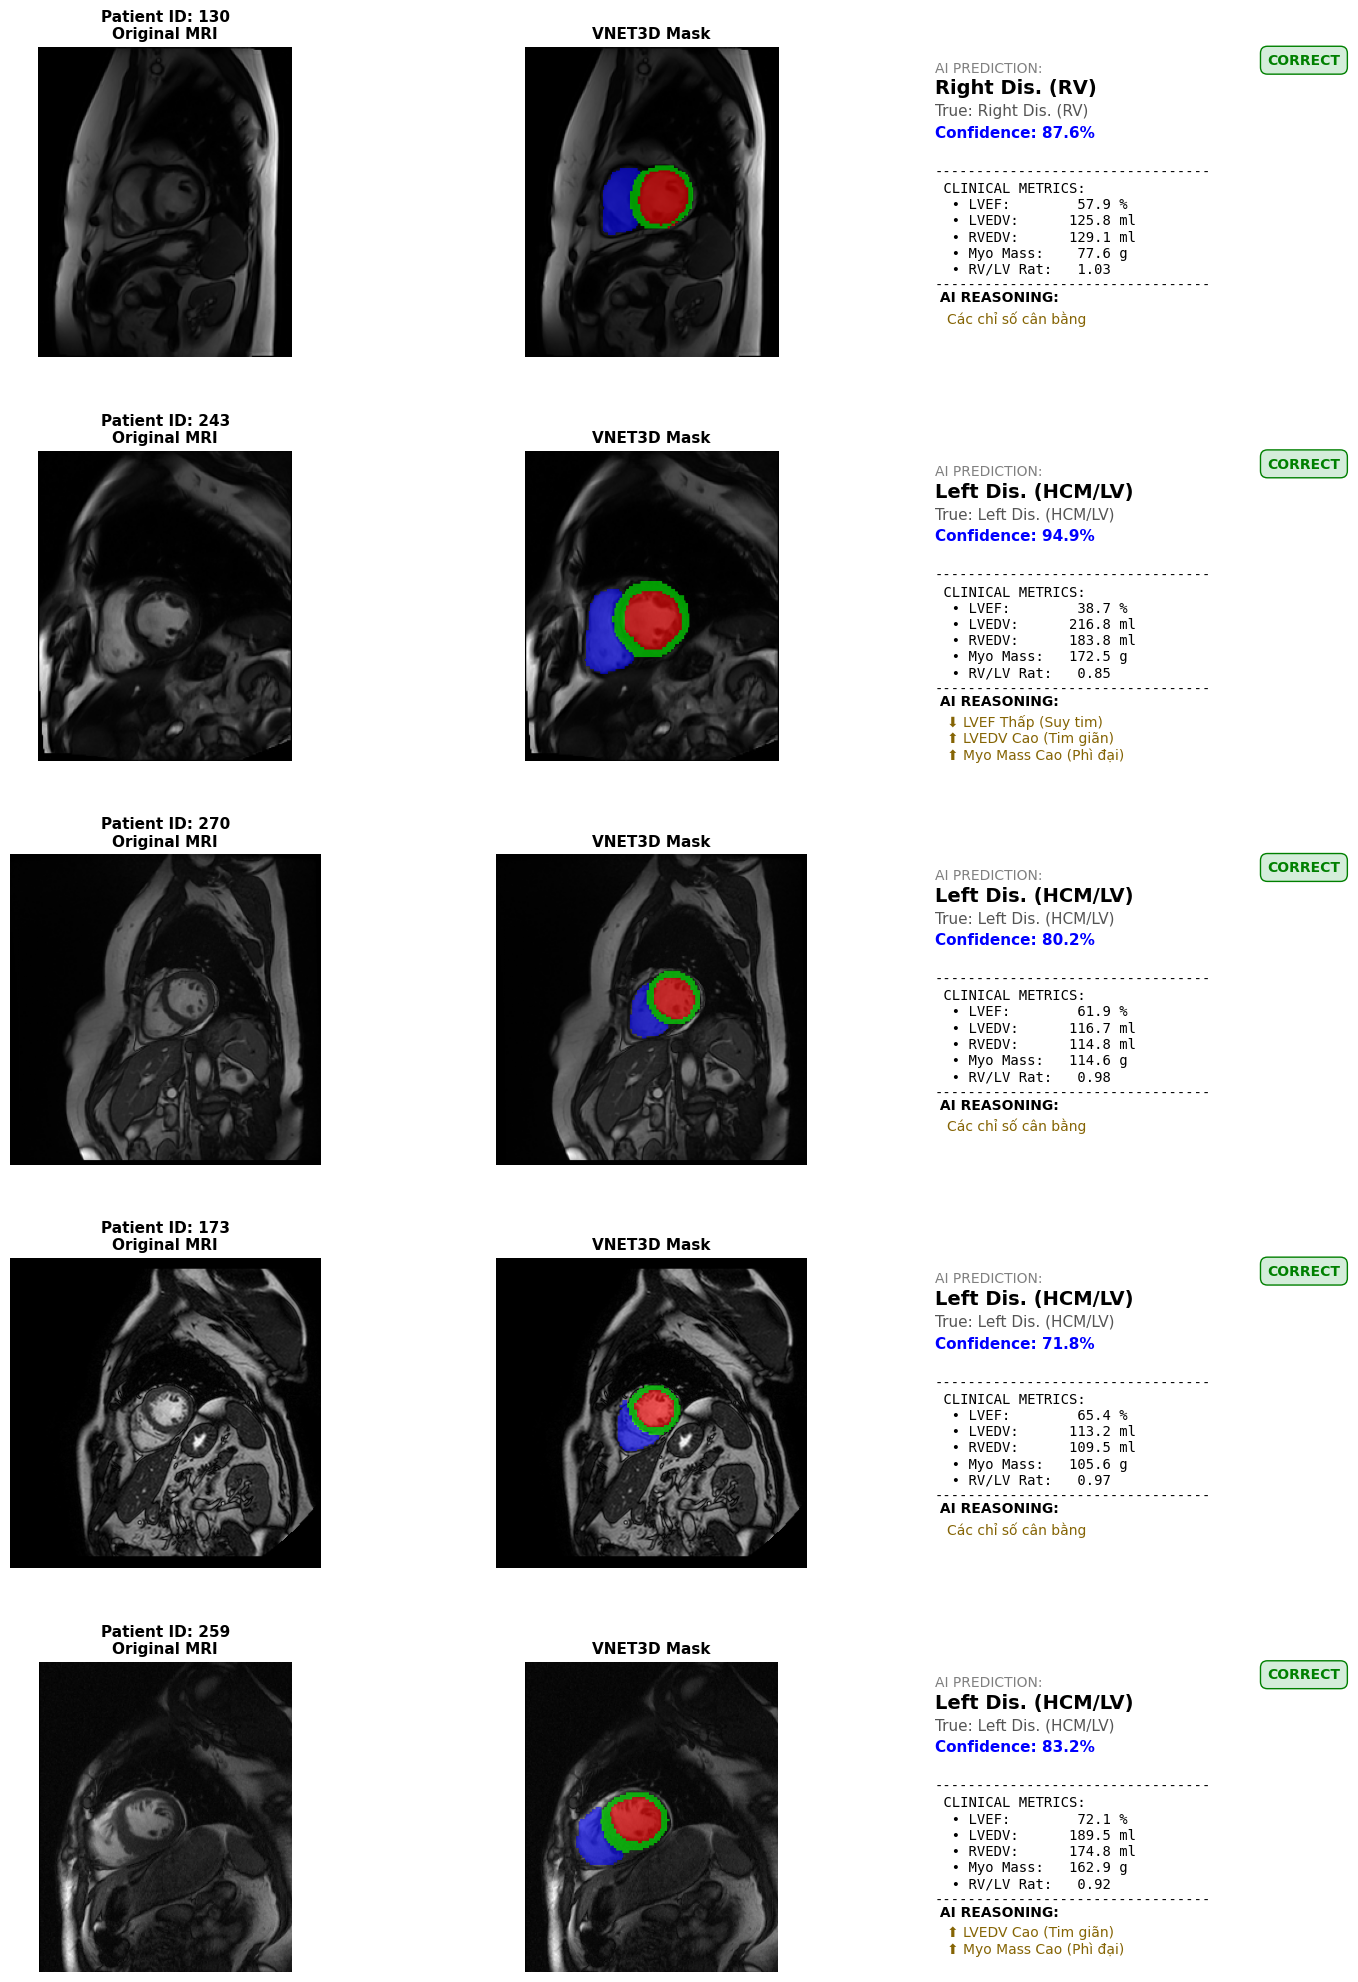

In [ ]:
# =============================================================================
# FINAL PIPELINE: PHÂN LOẠI 3 NHÓM BỆNH (VNET3D/SEGRESNET -> RADIOMICS + DEEP FEATURE -> ENSEMBLE)
# =============================================================================

import os
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from itertools import cycle
from matplotlib.colors import ListedColormap 

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

# --- CẤU HÌNH ---
CONFIG = {
    'DATA_ROOT': '/kaggle/input/m-and-ms-dataset/MnM2/dataset',
    'CSV_INFO': '/kaggle/input/m-and-ms-dataset/MnM2/dataset_information.csv',
    'PRED_MASK_DIR': '/kaggle/input/vnet3d-masks', 
    'SAVED_DEEP_FEATURES': '/kaggle/input/csv-phanloai/Heart_Disease_Features_Final.csv',
    'SEED': 42
}

# =============================================================================
# PHẦN 1: CÁC HÀM XỬ LÝ DỮ LIỆU & RADIOMICS
# =============================================================================

def clean_subject_code(val):
    try:
        s = str(val).strip()
        if '.' in s: s = s.split('.')[0]
        return s
    except: return None

def update_vnet_paths(df, mask_dir):
    print(f"📂 Đang quét mask từ: {mask_dir}")
    def _find_path(row):
        subj_id = str(row['SUBJECT_CODE']).strip()
        p_ed = os.path.join(mask_dir, f"{subj_id}_SA_ED_mask.nii")
        p_es = os.path.join(mask_dir, f"{subj_id}_SA_ES_mask.nii")
        if os.path.exists(p_ed) and os.path.exists(p_es): return [p_ed, p_es]
        return [None, None]

    df_new = df.copy()
    paths_series = df_new.apply(_find_path, axis=1)
    df_new['Mask_ED_Path'] = paths_series.apply(lambda x: x[0])
    df_new['Mask_ES_Path'] = paths_series.apply(lambda x: x[1])
    return df_new.dropna(subset=['Mask_ED_Path', 'Mask_ES_Path']).copy()

def calculate_radiomics_vnet(row):
    try:
        mask_ed = nib.load(row['Mask_ED_Path'])
        mask_es = nib.load(row['Mask_ES_Path'])
        ed_data, es_data = mask_ed.get_fdata(), mask_es.get_fdata()
        zooms = mask_ed.header.get_zooms()
        voxel_vol = np.prod(zooms) / 1000.0 
        
        lvedv = np.sum(ed_data == 1) * voxel_vol
        lvesv = np.sum(es_data == 1) * voxel_vol
        lvef = (lvedv - lvesv) / lvedv if lvedv > 0 else 0
        myo_mass = np.sum(ed_data == 2) * voxel_vol * 1.05
        rvedv = np.sum(ed_data == 3) * voxel_vol
        
        rv_lv_ratio = rvedv / lvedv if lvedv > 0 else 0
        mass_vol_ratio = myo_mass / lvedv if lvedv > 0 else 0
        return pd.Series([lvedv, lvef, myo_mass, rvedv, rv_lv_ratio, mass_vol_ratio])
    except: return pd.Series([0]*6)

def map_labels(disease):
    d = str(disease).upper().strip()
    if d in ['HCM', 'LV', 'HYPERTROPHIC CARDIOMYOPATHY']: return 0
    elif d in ['RV', 'ARR', 'CIA', 'FALL', 'TRI']: return 1
    elif d in ['NOR', 'NORMAL']: return 2
    return -1

# =============================================================================
# PHẦN 2: CÁC HÀM VẼ BIỂU ĐỒ (VISUALIZATION)
# =============================================================================

def plot_multiclass_roc(y_test, y_score, n_classes, class_names):
    y_test_bin = label_binarize(y_test, classes=range(n_classes))
    fpr, tpr, roc_auc = dict(), dict(), dict()
    plt.figure(figsize=(10, 6))
    colors = cycle(['blue', 'red', 'green'])
    for i, color in zip(range(n_classes), colors):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], color=color, lw=2, label='ROC {0} (AUC = {1:0.2f})'.format(class_names[i], roc_auc[i]))
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.legend(loc="lower right")
    plt.title('Biểu đồ ROC đa lớp')
    plt.show()

def plot_feature_importance(ensemble_model, feature_names):
    try:
        rf_model = ensemble_model.named_estimators_['rf']
        importances = rf_model.feature_importances_
        indices = np.argsort(importances)[::-1][:15]
        plt.figure(figsize=(12, 6))
        plt.bar(range(len(indices)), importances[indices], align="center", color='teal')
        plt.xticks(range(len(indices)), [feature_names[i] for i in indices], rotation=45, ha='right')
        plt.title("Top 15 Đặc trưng quan trọng nhất")
        plt.show()
    except: pass

def get_middle_slice_viz(path):
    try:
        img = nib.load(path)
        data = img.get_fdata()
        if len(data.shape) == 4: data = data[..., 0]
        return data[:, :, data.shape[2] // 2]
    except: return np.zeros((100, 100))

# --- HÀM TRỰC QUAN HÓA (ĐÃ SỬA LỖI RES_FG) ---
# =============================================================================
# CẬP NHẬT: VISUALIZATION
# =============================================================================

def visualize_samples_overlay(df, model, scaler, feature_names, n_samples=5):
    """
    Hiển thị kết quả với bố cục đã được căn chỉnh khoảng cách (Padding fix)
    """
    print(f"\n TRỰC QUAN HÓA {n_samples} BỆNH NHÂN:")
    
    sample_df = df.sample(n=n_samples, random_state=42)
    X_sample_s = scaler.transform(sample_df[feature_names].values)
    y_pred = model.predict(X_sample_s)
    y_proba = model.predict_proba(X_sample_s)
    y_true = sample_df['Label_ID'].values
    
    class_map = {0: 'Left Dis. (HCM/LV)', 1: 'Right Dis. (RV)', 2: 'Normal'}
    colors = [(0,0,0,0), (1,0,0,0.6), (0,1,0,0.6), (0,0,1,0.6)]
    cmap_overlay = ListedColormap(colors)

    fig, axes = plt.subplots(nrows=n_samples, ncols=3, figsize=(18, 5 * n_samples))
    plt.subplots_adjust(wspace=0.15, hspace=0.3)
    if n_samples == 1: axes = [axes]
    
    for i, (idx, row) in enumerate(sample_df.iterrows()):
        # --- CHUẨN BỊ ẢNH ---
        sid = str(row['SUBJECT_CODE'])
        img_path = os.path.join(CONFIG['DATA_ROOT'], sid, f"{sid}_SA_ED.nii.gz")
        if not os.path.exists(img_path): img_path = os.path.join(CONFIG['DATA_ROOT'], sid, f"{sid}_SA_ED.nii")
        
        mri_slice = get_middle_slice_viz(img_path)
        mask_slice = get_middle_slice_viz(row['Mask_ED_Path'])
        
        # Cột 1 & 2: Ảnh & Overlay (Giữ nguyên)
        axes[i][0].imshow(mri_slice, cmap='gray')
        axes[i][0].set_title(f"Patient ID: {sid}\nOriginal MRI", fontsize=11, fontweight='bold')
        axes[i][0].axis('off')
        
        axes[i][1].imshow(mri_slice, cmap='gray')
        axes[i][1].imshow(mask_slice, cmap=cmap_overlay, vmin=0, vmax=3)
        axes[i][1].set_title("VNET3D Mask", fontsize=11, fontweight='bold')
        axes[i][1].axis('off')
        
        # --- CỘT 3: MEDICAL REPORT (CĂN CHỈNH LẠI TỌA ĐỘ) ---
        true_lab = class_map[y_true[i]]
        pred_lab = class_map[y_pred[i]]
        conf = np.max(y_proba[i]) * 100
        is_correct = (y_true[i] == y_pred[i])
        
        res_bg = '#d4edda' if is_correct else '#f8d7da' 
        res_fg = 'green' if is_correct else 'red'
        res_text = "CORRECT" if is_correct else "WRONG"

        axes[i][2].axis('off')
        
        # 1. BOX KẾT QUẢ (Góc trên phải)
        axes[i][2].text(0.98, 0.98, res_text, fontsize=10, fontweight='bold', color=res_fg, ha='right', va='top',
                        bbox=dict(facecolor=res_bg, edgecolor=res_fg, boxstyle='round,pad=0.5'))

        # 2. THÔNG TIN CHẨN ĐOÁN (0.90 -> 0.65)
        axes[i][2].text(0.02, 0.92, "AI PREDICTION:", fontsize=10, color='gray', ha='left')
        axes[i][2].text(0.02, 0.85, pred_lab, fontsize=14, fontweight='bold', color='black', ha='left')
        axes[i][2].text(0.02, 0.78, f"True: {true_lab}", fontsize=11, color='#555', ha='left')
        axes[i][2].text(0.02, 0.71, f"Confidence: {conf:.1f}%", fontsize=11, fontweight='bold', color='blue', ha='left')
        
        # 3. BẢNG CHỈ SỐ (Đẩy lên cao hơn: 0.55)
        ef = row['LVEF'] * 100
        lvedv = row['LVEDV']
        rvedv = row['RVEDV']
        ratio = row['RV_LV_Ratio']
        mass = row['MYO_MASS']
        
        metrics_text = (
            f"---------------------------------\n"
            f" CLINICAL METRICS:\n"
            f"  • LVEF:       {ef:>5.1f} %\n"
            f"  • LVEDV:      {lvedv:>5.1f} ml\n"
            f"  • RVEDV:      {rvedv:>5.1f} ml\n"
            f"  • Myo Mass:   {mass:>5.1f} g\n"
            f"  • RV/LV Rat:  {ratio:>5.2f}\n"
            f"---------------------------------"
        )
        # va='top' để text mọc xuống dưới
        axes[i][2].text(0.02, 0.62, metrics_text, fontsize=10, family='monospace', va='top')
        
        # 4. GỢI Ý CHẨN ĐOÁN (Đẩy xuống thấp hơn và tách biệt: 0.25)
        clues = []
        if ef < 40: clues.append("⬇️ LVEF Thấp (Suy tim)")
        if lvedv > 150: clues.append("⬆️ LVEDV Cao (Tim giãn)")
        if mass > 150: clues.append("⬆️ Myo Mass Cao (Phì đại)")
        if ratio > 1.2: clues.append("⬆️ RV/LV > 1.2 (Lệch phải)")
        if not clues: clues.append("Các chỉ số cân bằng")
        explanation = "\n".join(clues)
        
        # Tiêu đề ở 0.25
        axes[i][2].text(0.02, 0.18, " AI REASONING:", fontsize=10, fontweight='bold')
        # Nội dung ở 0.22, va='top' (mọc xuống dưới) -> KHÔNG BAO GIỜ ĐÈ LÊN TIÊU ĐỀ NỮA
        axes[i][2].text(0.05, 0.15, explanation, fontsize=10, color='#856404', va='top')

    plt.show()

# =============================================================================
# PHẦN 3: PIPELINE CHÍNH
# =============================================================================

def run_full_system():
    print(" BẮT ĐẦU HỆ THỐNG PHÂN LOẠI TIM MẠCH TỰ ĐỘNG")
    print("="*60)
    
    # 1. LOAD & MERGE
    print("\n--- BƯỚC 1: TẢI DỮ LIỆU ---")
    df_info = pd.read_csv(CONFIG['CSV_INFO']).dropna(subset=['SUBJECT_CODE'])
    df_info['SUBJECT_CODE'] = df_info['SUBJECT_CODE'].apply(clean_subject_code)
    
    if not os.path.exists(CONFIG['SAVED_DEEP_FEATURES']):
        return print("⚠️ Thiếu file Deep Features!")
        
    df_deep = pd.read_csv(CONFIG['SAVED_DEEP_FEATURES']).dropna(subset=['SUBJECT_CODE'])
    df_deep['SUBJECT_CODE'] = df_deep['SUBJECT_CODE'].apply(clean_subject_code)
    deep_cols = [c for c in df_deep.columns if 'Deep_' in c]
    
    df_merged = df_info.merge(df_deep[['SUBJECT_CODE'] + deep_cols], on='SUBJECT_CODE', how='inner')
    print(f"   -> Số lượng bệnh nhân: {len(df_merged)}")
    
    # 2. RADIOMICS
    print("\n--- BƯỚC 2: TÍNH RADIOMICS ---")
    df_vnet = update_vnet_paths(df_merged, CONFIG['PRED_MASK_DIR'])
    if len(df_vnet) == 0: return print("❌ Không tìm thấy mask!")
    
    rad_cols = ['LVEDV', 'LVEF', 'MYO_MASS', 'RVEDV', 'RV_LV_Ratio', 'Mass_Vol_Ratio']
    print("⏳ Đang tính toán chỉ số y sinh...")
    try:
        df_vnet[rad_cols] = df_vnet.apply(calculate_radiomics_vnet, axis=1)
    except:
        temp = df_vnet.apply(calculate_radiomics_vnet, axis=1)
        for i, c in enumerate(rad_cols): df_vnet[c] = temp.apply(lambda x: x[i])
        
    df_valid = df_vnet[df_vnet['LVEDV'] > 0].copy()
    print(f"✅ Dữ liệu hợp lệ: {len(df_valid)}")
    
    # 3. TRAIN
    print("\n--- BƯỚC 3: HUẤN LUYỆN ---")
    df_valid['Label_ID'] = df_valid['DISEASE'].apply(map_labels)
    df_ml = df_valid[df_valid['Label_ID'] != -1].copy()
    
    feature_cols = rad_cols + deep_cols
    X = df_ml[feature_cols].values
    y = df_ml['Label_ID'].values
    class_names = ['Left Path', 'Right Path', 'Normal']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=CONFIG['SEED'], stratify=y) #đảm bảo rằng tỷ lệ bệnh nhân bị bệnh và bình thường được chia đều cho cả 2 tập
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    
    try: X_train_bal, y_train_bal = SMOTE(random_state=42, k_neighbors=3).fit_resample(X_train_s, y_train)
    except: X_train_bal, y_train_bal = X_train_s, y_train
    
    clf_xgb = xgb.XGBClassifier(
        objective='multi:softmax', 
        num_class=3, n_estimators=200, 
        max_depth=4, learning_rate=0.05, 
        use_label_encoder=False, 
        eval_metric='mlogloss', 
        random_state=42)
    
    clf_rf = RandomForestClassifier(
        n_estimators=200, 
        max_depth=10, 
        random_state=42)
    clf_svc = SVC(
        kernel='rbf', 
        probability=True,
        C=1.0,
        random_state=42)
    ensemble = VotingClassifier(estimators=[('xgb', clf_xgb), ('rf', clf_rf), ('svc', clf_svc)], voting='soft')
    ensemble.fit(X_train_bal, y_train_bal)
    
    # 4. RESULTS
    y_pred = ensemble.predict(X_test_s)
    y_proba = ensemble.predict_proba(X_test_s)
    acc = accuracy_score(y_test, y_pred)
    
    print(f"\n🏆 ĐỘ CHÍNH XÁC: {acc*100:.2f}%")
    print("-" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
    
    # --- VẼ HÌNH ---
    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix')
    plt.show()
    
    plot_multiclass_roc(y_test, y_proba, 3, class_names)
    plot_feature_importance(ensemble, feature_cols)
    
    # GỌI HÀM VISUALIZE MỚI
    visualize_samples_overlay(df_ml, ensemble, scaler, feature_cols, n_samples=5)

if __name__ == "__main__":
    run_full_system()